# 05 — Avaliação da segmentação de colaboradores
**CRISP-DM — Fase 5 | IBM HR Analytics**

Objetivo: verificar a qualidade dos clusters do notebook 04, interpretar os perfis de RH, revisar a integridade dos arquivos e registrar uma decisão para o notebook 06.

`Desligamento` é uma variável **externa**: não participa do agrupamento. As métricas descrevem associações, não causalidade. Não serão importados critérios de aceitação do projeto imobiliário.

## 0. Importações e arquivos

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_samples

DADOS = Path('../data/processed')
MODELOS = Path('../models')
TABELAS = Path('../reports/tables/rh')
FIGURAS = Path('../reports/figures/rh')
TABELAS.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)

arquivos = {
    'matriz': DADOS / 'base_rh_preprocessed.csv',
    'perfil': DADOS / 'base_rh_perfil.csv',
    'segmentos': DADOS / 'segmentos_rh.csv',
    'colaboradores': DADOS / 'colaboradores_segmentados_rh.csv',
    'modelo': MODELOS / 'selecionado_rh.json',
}
for caminho in arquivos.values():
    if not caminho.exists():
        raise FileNotFoundError(f'Arquivo ausente: {caminho}. Execute 03 e 04.')

X = pd.read_csv(arquivos['matriz'], sep=';')
perfil = pd.read_csv(arquivos['perfil'], sep=';')
segmentos = pd.read_csv(arquivos['segmentos'], sep=';')
colaboradores = pd.read_csv(arquivos['colaboradores'], sep=';')
modelo = json.loads(arquivos['modelo'].read_text(encoding='utf-8'))
print('Matriz:', X.shape, '| Modelo:', modelo['modelo'])

Matriz: (1470, 51) | Modelo: dbscan


## 1. Reexaminar a modelagem
Conferir se os arquivos correspondem à mesma execução e calcular a silhueta dos segmentos, desconsiderando ruído (`-1`) quando houver.

In [2]:
if not (len(X) == len(perfil) == len(segmentos) == len(colaboradores)):
    raise ValueError('Quantidade de registros divergente')
if not X.select_dtypes(exclude='number').empty or X.isna().any().any():
    raise ValueError('Matriz deve conter somente números sem valores ausentes')
if not np.isfinite(X.to_numpy(dtype=float)).all():
    raise ValueError('Matriz contém valores não finitos')
if any('Desligamento' in c or 'Numero_do_Funcionario' in c for c in X.columns):
    raise ValueError('Variável externa ou identificador incluído na matriz')
if X.columns.tolist() != modelo['atributos'] or X.shape != (modelo['n_amostras'], modelo['n_atributos']):
    raise ValueError('Matriz não corresponde aos metadados do notebook 04')
if 'segmento' not in segmentos or 'segmento' not in colaboradores:
    raise ValueError('Coluna segmento não encontrada')
rotulos = segmentos['segmento'].to_numpy()
if not np.array_equal(rotulos, colaboradores['segmento'].to_numpy()):
    raise ValueError('Rótulos divergentes entre as bases')
if not perfil.reset_index(drop=True).equals(colaboradores[perfil.columns].reset_index(drop=True)):
    raise ValueError('Colaboradores e perfis não estão alinhados')

validos = rotulos != -1
if not 2 <= len(np.unique(rotulos[validos])) < validos.sum():
    raise ValueError('Partição sem pelo menos 2 clusters válidos')
valores = silhouette_samples(X.to_numpy(dtype=float)[validos], rotulos[validos])
silhueta = float(valores.mean())
silhueta_04 = float(modelo['silhueta'])
if abs(silhueta - silhueta_04) > 0.01:
    raise ValueError('Silhueta diverge do notebook 04')

qualidade = pd.DataFrame({'segmento': rotulos[validos], 'silhueta': valores})
qualidade = qualidade.groupby('segmento').agg(
    colaboradores=('silhueta', 'size'),
    silhueta_media=('silhueta', 'mean'),
    silhueta_negativa=('silhueta', lambda s: (s < 0).mean()),
).reset_index()
qualidade['percentual'] = qualidade['colaboradores'] / len(X) * 100
qualidade.to_csv(TABELAS / '05_silhueta_por_segmento.csv', sep=';', index=False)
print(f'Silhueta: {silhueta:.4f} | Ruído: {(~validos).sum()} registros')
display(qualidade)

Silhueta: 0.1144 | Ruído: 241 registros


,segmento,colaboradores,silhueta_media,silhueta_negativa,percentual
0,0,833,0.096952,0.001200,56.666667
1,1,374,0.141116,0.002674,25.442177
2,2,22,0.320080,0.000000,1.496599


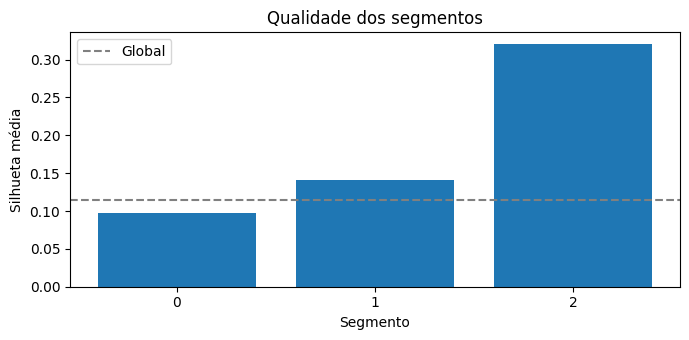

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(qualidade['segmento'].astype(str), qualidade['silhueta_media'])
ax.axhline(silhueta, linestyle='--', color='gray', label='Global')
ax.set(xlabel='Segmento', ylabel='Silhueta média', title='Qualidade dos segmentos')
ax.legend()
fig.tight_layout()
fig.savefig(FIGURAS / '05_silhueta_por_segmento.png', dpi=130)
plt.show()

## 2. Avaliar resultados de RH
Comparar características básicas dos colaboradores e a proporção de desligamentos por segmento. `Desligamento` não é usado para definir os clusters.

In [4]:
necessarias = ['Idade', 'Renda_Mensal', 'Anos_na_Empresa', 'Desligamento']
if any(c not in colaboradores for c in necessarias):
    raise ValueError('Faltam colunas necessárias para avaliar os perfis')

rh = colaboradores.copy()
texto = rh['Desligamento'].astype(str).str.strip().str.lower()
if not texto.isin(['sim', 'não', 'nao']).all():
    raise ValueError('Categoria inesperada em Desligamento')
rh['desligou'] = texto.eq('sim').astype(int)

perfis = rh.groupby('segmento').agg(
    colaboradores=('Desligamento', 'size'),
    idade_mediana=('Idade', 'median'),
    renda_mediana=('Renda_Mensal', 'median'),
    anos_empresa_mediana=('Anos_na_Empresa', 'median'),
    taxa_desligamento=('desligou', 'mean'),
).reset_index()
perfis['percentual'] = perfis['colaboradores'] / len(rh) * 100
perfis.to_csv(TABELAS / '05_perfis_e_desligamento.csv', sep=';', index=False)
display(perfis)

for coluna in ['Departamento', 'Cargo', 'Satisfacao_no_Trabalho', 'Equilibrio_Vida_Pessoal_Profissional']:
    if coluna in rh:
        distribuicao = pd.crosstab(rh['segmento'], rh[coluna], normalize='index').reset_index()
        distribuicao.to_csv(TABELAS / f'05_distribuicao_{coluna.lower()}.csv', sep=';', index=False)

,segmento,colaboradores,idade_mediana,renda_mediana,anos_empresa_mediana,taxa_desligamento,percentual
0,-1,241,40.0,9756.0,7.0,0.186722,16.394558
1,0,833,35.0,3986.0,5.0,0.141657,56.666667
2,1,374,35.0,5885.5,5.5,0.184492,25.442177
3,2,22,34.0,3668.5,4.0,0.227273,1.496599


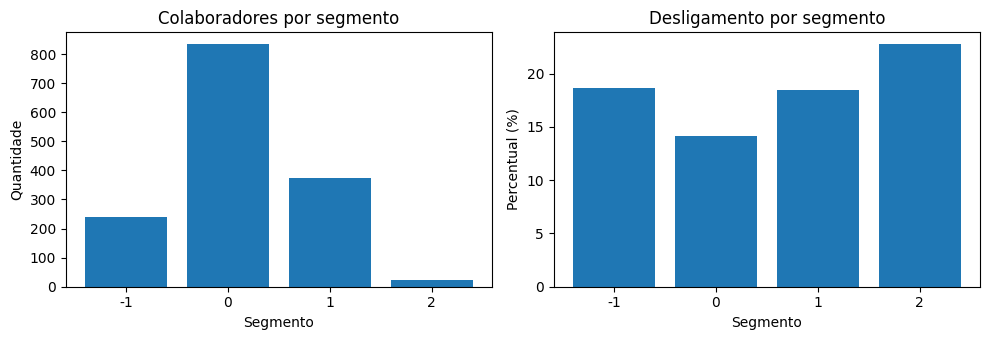

In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(10, 3.5))
eixos[0].bar(perfis['segmento'].astype(str), perfis['colaboradores'])
eixos[0].set(title='Colaboradores por segmento', xlabel='Segmento', ylabel='Quantidade')
eixos[1].bar(perfis['segmento'].astype(str), perfis['taxa_desligamento'] * 100)
eixos[1].set(title='Desligamento por segmento', xlabel='Segmento', ylabel='Percentual (%)')
fig.tight_layout()
fig.savefig(FIGURAS / '05_tamanho_desligamento.png', dpi=130)
plt.show()

## 3. Revisar o processo
Registrar os arquivos utilizados e informações mínimas para que o notebook 06 possa verificar se os dados mudaram após a avaliação.

In [6]:
hashes = {
    caminho.name: hashlib.sha256(caminho.read_bytes()).hexdigest()
    for caminho in arquivos.values()
}
auditoria = {
    'n_registros': len(X),
    'n_atributos': X.shape[1],
    'n_segmentos': int(qualidade.shape[0]),
    'ruido_n': int((~validos).sum()),
    'silhueta_recalculada': silhueta,
    'silhueta_modelo04': silhueta_04,
    'variavel_externa_excluida': True,
    'alinhamento_perfil': True,
    'arquivos_sha256': hashes,
}
MODELOS.mkdir(parents=True, exist_ok=True)
(MODELOS / 'auditoria_rh_05.json').write_text(
    json.dumps(auditoria, indent=2, ensure_ascii=False), encoding='utf-8'
)
pd.DataFrame([{'arquivo': k, 'sha256': v} for k, v in hashes.items()]).to_csv(
    TABELAS / '05_manifesto_entradas.csv', sep=';', index=False
)
print('Auditoria registrada')

Auditoria registrada


## 4. Decisão e próximas etapas
Sem critérios de aceitação previamente aprovados para RH, a decisão inicial é **revisão pendente**. Uma aprovação exige análise e justificativa humana. O notebook 06 usa `avaliacao_rh.json` para permitir ou impedir o empacotamento.

In [7]:
DECISAO = 'revisao_pendente'  # aprovado | revisao_pendente | rejeitado
JUSTIFICATIVA = 'Aguardando revisão dos resultados e definição dos critérios de aceitação.'

if DECISAO not in {'aprovado', 'revisao_pendente', 'rejeitado'}:
    raise ValueError('Decisão inválida')
if DECISAO == 'aprovado' and (not JUSTIFICATIVA.strip() or 'Aguardando' in JUSTIFICATIVA):
    raise ValueError('A aprovação exige justificativa específica')

avaliacao = {
    'decisao': DECISAO,
    'justificativa': JUSTIFICATIVA,
    'algoritmo': modelo['modelo'],
    'modelo_arquivo': modelo['arquivo'],
    'silhueta': silhueta,
    'grupos': int(len(qualidade)),
    'registros': len(X),
    'auditoria': 'auditoria_rh_05.json',
    'observacao': 'Desligamento é análise externa; as diferenças não demonstram causalidade.',
    'entradas_sha256': hashes,
}
(MODELOS / 'avaliacao_rh.json').write_text(
    json.dumps(avaliacao, indent=2, ensure_ascii=False), encoding='utf-8'
)
print('Decisão:', DECISAO, '| Próxima etapa: notebook 06')

Decisão: revisao_pendente | Próxima etapa: notebook 06
